# NB05 — Grafos de nodos por capas (micro → meso → macro)

Estudio de figuras de grafos de nodos **en tres capas**, por instrucción de
rmw3 (2026-10-09: "sería bueno hacer un notebook que estudie en forma
separada los gráficos de los grafos de nodos… desde micro a macro").

**Fuentes** (todas bajo `data/`, con denominadores en cada loader — R10):

| capa | fuente | n |
|---|---|---|
| micro | `traces_sample.jsonl` = últimas 3 evaluaciones socratic de `tree_traces.jsonl`; **regla documentada:** se excluyen los audits `claim_gate` rutinarios (2042 de 7432) | 3 de 5390 candidatas (muestra) |
| meso | `sidecars/*.claims.vsm` + `*.depth.vsm` | 12 sidecars (7 claims + 5 depth) |
| macro | gaps (6) + RULES pointer (20 reglas) + paper_data (15 EXP) + current_focus (decisiones) + traces | censo completo salvo predicates/answers (muestra marcada) |

**Herramienta:** `graph_study.py` — loaders con `(objs, stats)`, layouts
fijos (sin aleatoriedad, R10) y renderers matplotlib puros (sin networkx →
portable a LXC 114). El loader de predicados es espejo local de
`trace_graph.per_trace` (identidad F3: clave = texto VSL, nunca id local
por-trace).

## ① MICRO — un trace: árbol de predicados (una evaluación socratic)

Capa más fina: **un solo `socratic_evaluate`** como grafo con sus aristas
`children`. Coloreamos por `truth` (paleta espejo de trace_graph: TRUE verde,
FALSE rojo, UNKNOWN gris).

meta muestra: {"source": "state/rsi/tree_traces.jsonl", "source_total": 7432, "claim_gate_excluded": 2042, "candidates": 5390, "rule": "last-k non-claim_gate traces (deterministic, k=3)", "skipped_bad_json": 0, "dropped_no_nodes": 0, "kept": 3}
archivo muestra: {'total': 3, 'kept': 3, 'skipped': 0, 'dropped_no_nodes': 0}
por trace: [('trace-1791604846640-2460242', 11, 'OR(AND(ctx_has, ctx_has, ctx_contains, NOT(...)), AND(ctx_has, ctx_has, ctx_contains, NOT(...)))'), ('trace-1791604850982-2460271', 6, 'OR(AND(ctx_has, OR(..., ...)))'), ('trace-1791604855540-2460277', 4, 'OR(AND(ctx_has, ctx_contains))')]
elegido: {'trace_id': 'trace-1791604846640-2460242', 'ts': '2026-10-10T04:00:46.640909+00:00', 'final_truth': 'FALSE', 'shape': 'OR(AND(ctx_has, ctx_has, ctx_contains, NOT(...)), AND(ctx_has, ctx_has, ctx_contains, NOT(...)))'}
nodos=11 aristas=10 truths={'FALSE': 5, 'TRUE': 4, 'UNKNOWN': 2}


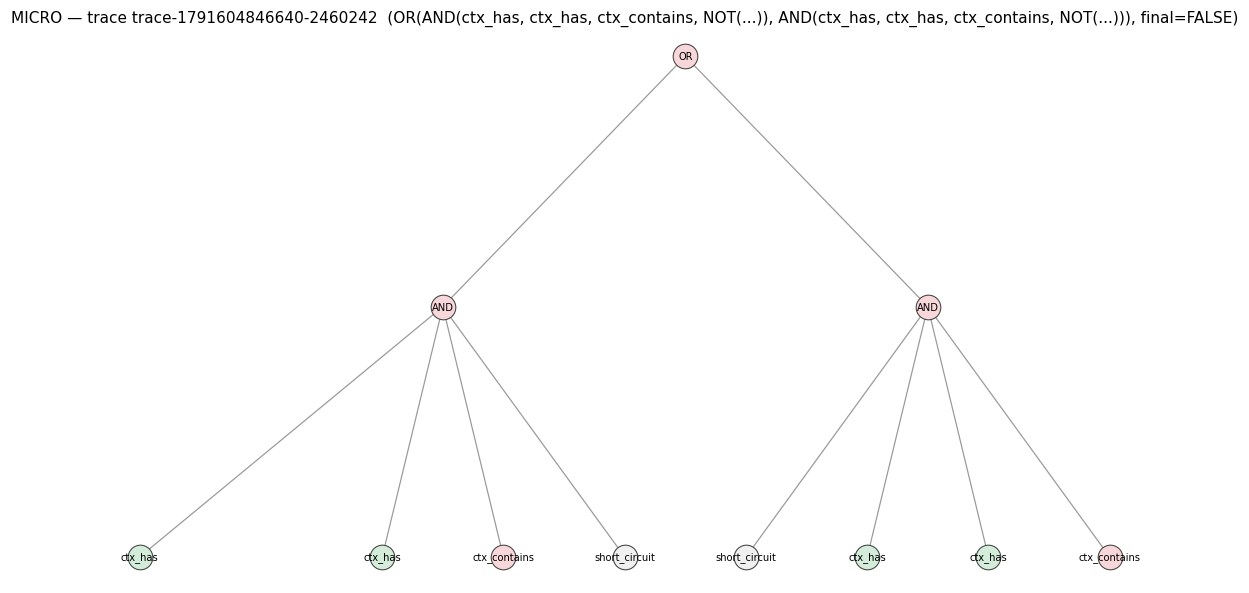

In [ ]:
%matplotlib inline
import sys, io, json
from pathlib import Path
sys.path.insert(0, ".")
import matplotlib.pyplot as plt
from graph_study import load_trace_sample, per_trace_graph, draw_tree

meta = json.loads(Path("data/traces_sample.meta.json").read_text())
print("meta muestra:", json.dumps(meta, ensure_ascii=False))
traces, st = load_trace_sample("data/traces_sample.jsonl", k=3)
print("archivo muestra:", st)   # total/kept/skipped/dropped del archivo
print("por trace:", [(t.get("trace_id"), len(t["nodes"]),
                      t.get("tree_shape")) for t in traces])

# selección determinística: máx nº de nodos, empate → trace_id menor
pick = max(traces, key=lambda t: (len(t["nodes"]), t.get("trace_id", "")))
g = per_trace_graph(pick)
truths = {}
for n in g["nodes"]:
    truths[n["truth"]] = truths.get(n["truth"], 0) + 1
print("elegido:", g["meta"])
print(f"nodos={len(g['nodes'])} aristas={len(g['edges'])} truths={truths}")

fig, ax = plt.subplots(figsize=(10, 5.5))
draw_tree(ax, g, f"MICRO — trace {g['meta']['trace_id']}  "
                 f"({g['meta']['shape']}, final={g['meta']['final_truth']})")
fig.tight_layout()
plt.show()

### Lectura micro

- El árbol de una evaluación es **pequeño y poco profundo** (unos pocos
  niveles): la capa micro mide *una pregunta*, no el sistema.
- La distribución `truth` del trace elegido muestra qué pesa en la práctica
  (predicados aún `UNKNOWN` = sin certificar → deuda de certificación).
- Denominador honesto: 3 de 7429 traces — **muestra**, no censo. El censo de
  predicados vive en la capa macro abajo (y también es muestra, marcada).

## ② MESO — un documento: `main.tex` (375 claims agrupados por tipo + depth)

Capa intermedia: **un documento** como centro, sus claims como satélites
agrupados por `type` (375 labels individuales no son legibles → hubs con
conteo, hojas compactas). Al lado, las dimensiones `depth` del sidecar.

sidecars: {'docs': 8, 'claims_parsed': 509, 'claims_files_failed': 0, 'claims_files': 7, 'depth_files': 5, 'paired': 4}
main claims = 375  tipos = {'number': 245, 'theorem': 130}
risk: {'exploratory': 375}
depth levels: ['L1', 'L2', 'L3', 'L4', 'L5'] | verdict: full stack L1-L5 required (main)
depth evidence: {"theorem_envs": 17, "equation_envs": 42, "math_symbols": 385, "quant_claims": 138, "experiment_ids": 148, "measure_tokens": 184, "external_refs": 289, "numbered_sections": 0, "vsm_blocks": 0, "inequality_symbols": 98, "math_density": 1.61}


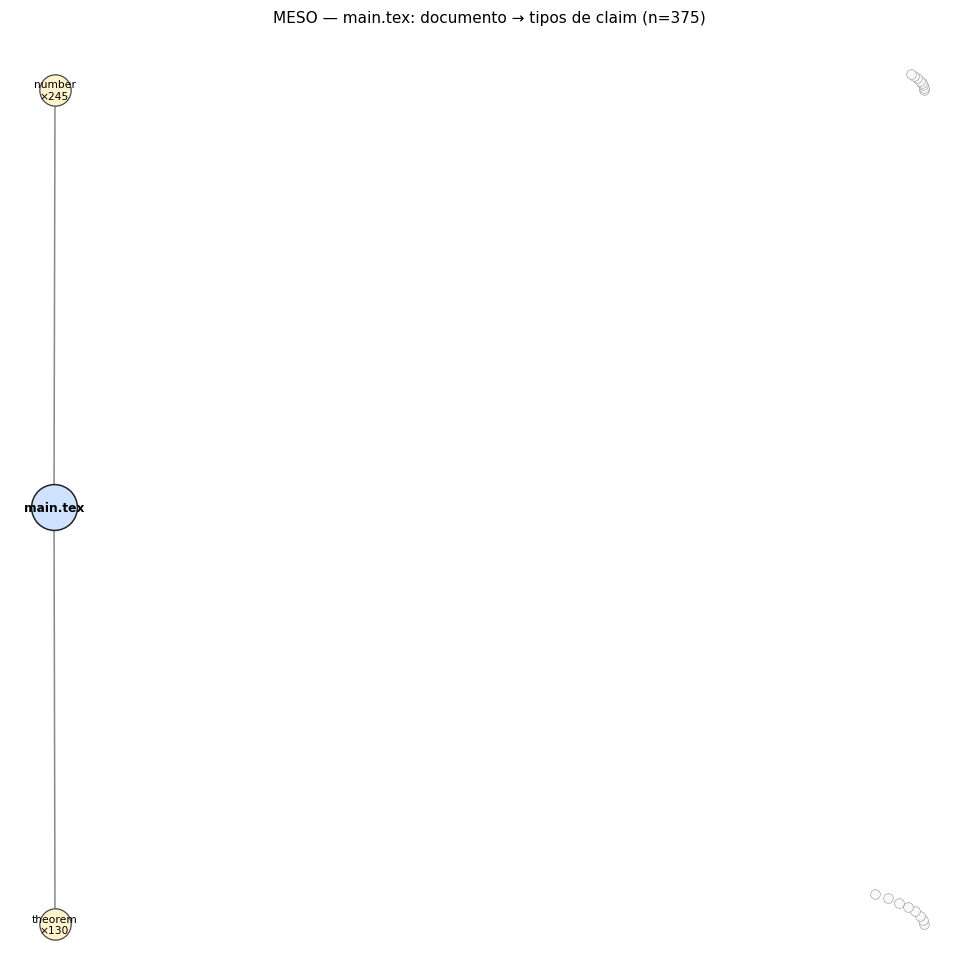

In [ ]:
from graph_study import load_sidecars, draw_radial, parse_vsm_assignments

docs, st_side = load_sidecars("data/sidecars")
print("sidecars:", st_side)   # docs/claims_parsed/claims_files_failed/depth_files

main = docs.get("main", {})
claims = main.get("claims", [])
by_type = {}
for c in claims:
    by_type.setdefault(c.get("type", "?"), []).append(c.get("id", "?"))
print(f"main claims = {len(claims)}  tipos = "
      f"{ {k: len(v) for k, v in sorted(by_type.items())} }")

# riesgos / subjects (denominador)
risks = {}
for c in claims:
    risks[c.get("risk", "?")] = risks.get(c.get("risk", "?"), 0) + 1
print("risk:", risks)

depth = parse_vsm_assignments(Path("data/sidecars/main.depth.vsm").read_text())
print("depth levels:", depth.get("levels"), "| verdict:", depth.get("verdict"))
print("depth evidence:", json.dumps(depth.get("evidence"), ensure_ascii=False))

fig, ax = plt.subplots(figsize=(9, 9))
draw_radial(ax, "main.tex", by_type,
            title="MESO — main.tex: documento → tipos de claim (n=375)")
fig.tight_layout()
plt.show()

### Lectura meso

- El documento central expone sus claims **por tipo** (hubs con `×N`): la
  forma del grafo meso = distribución de tipos, no cada claim.
- `main.depth.vsm` = L1–L5 **full stack** (verdict del estimator): el paper
  es el nodo mejor provisto del conjunto.
- Censo de sidecars: 6 archivos de claims (F1+F2) + 6 de depth — cada doc
  con su par claims/depth cuando existe (denominador `docs` en stats).

## ③ MACRO — censo del sistema: los 9 tipos de `graph_epistemic_proposal.vsm`

Capa más gruesa: **todas las fuentes** como columnas por `kind` (9 tipos
D1 aprobado por rmw3: document, claim, predicate, certificate, answer,
experiment, decision, gap, rule). Denominadores por fuente; `certificate`
se muestra **aunque esté vacío** (0 en el conjunto — hueco honesto que FASE-2
debe poblar).

claims por doc: {'addendum': 5, 'carta_acompanamiento': 5, 'claim_ingest_proposal': 0, 'lange_lerner_model': 68, 'main': 375, 'readme': 36, 'rev_prof_raul_fierro': 1, 'scope_arc_2026_10_02': 19} -> total: 509
  document     n=   8  stats={'claims_files': 7, 'depth_files': 5, 'paired': 4, 'claims_files_failed': 0}
  claim        n= 509  stats={'per_doc': {'addendum': 5, 'carta_acompanamiento': 5, 'claim_ingest_proposal': 0, 'lange_lerner_model': 68, 'main': 375, 'readme': 36, 'rev_prof_raul_fierro': 1, 'scope_arc_2026_10_02': 19}}
  predicate    n=  21  stats={'sampled': 3, 'candidates': 5390, 'source_total': 7432, 'claim_gate_excluded': 2042}
  certificate  n=   0  stats={'note': '0 emitidos — hueco FASE-2'}
  answer       n=   3  stats={'sampled_traces': 3}
  experiment   n=  15  stats={'count': 15}
  decision     n=  48  stats={'count': 48, 'active': 1}
  gap          n=   6  stats={'count': 6, 'dir': 'data/gaps'}
  rule         n=  20  stats={'count': 20}


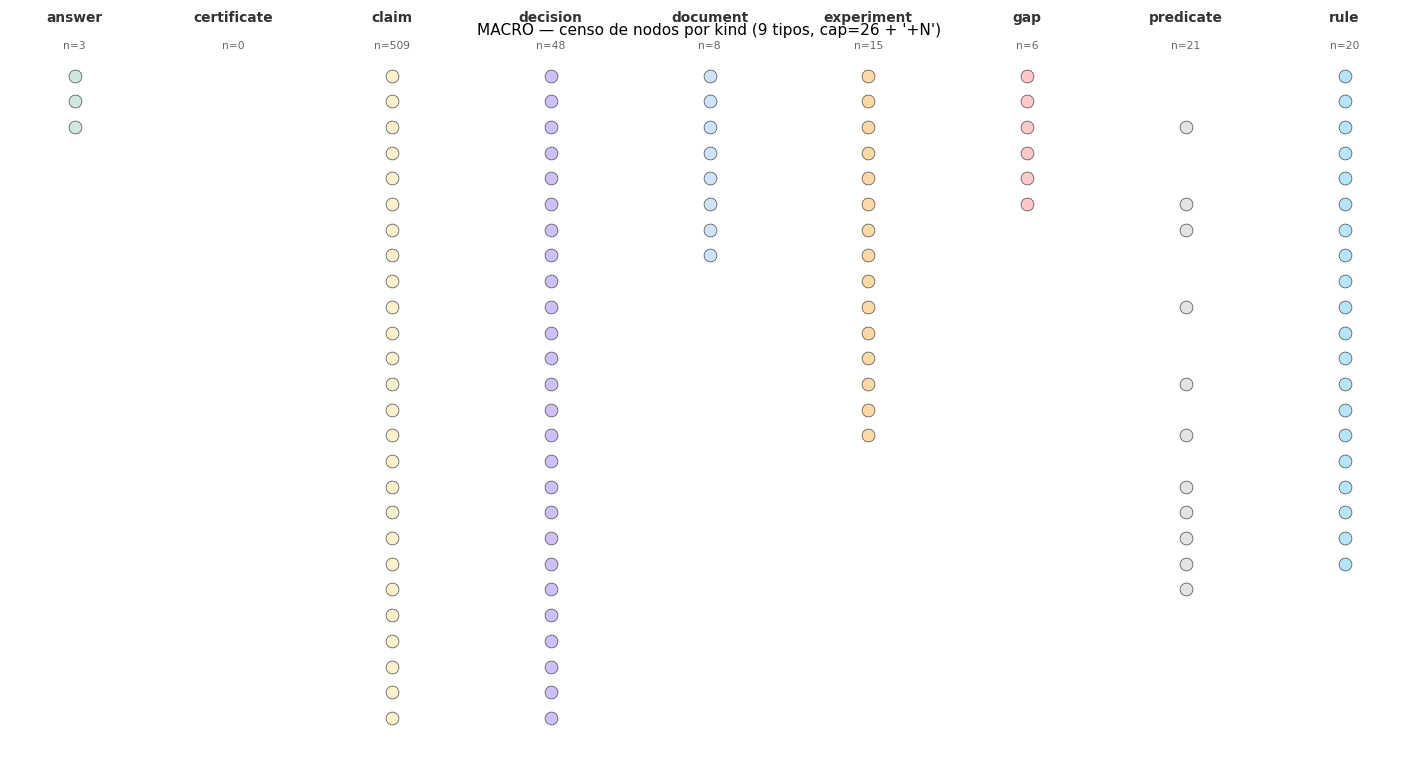

In [ ]:
from graph_study import (load_gaps, load_rules, load_experiments,
                         load_decisions, macro_census, draw_layers)

gaps, st_g = load_gaps("data/gaps")
rules, st_r = load_rules("data/rules_pointer.md")
exps, st_e = load_experiments("data/paper_data.vsm")
decs, st_d = load_decisions("data/current_focus.json")

# claims de TODOS los sidecars (cada uno con su denominador individual)
all_claims, per_doc = [], {}
for name, d in sorted(docs.items()):
    ids = [c.get("id", "?") for c in d.get("claims", [])]
    per_doc[name] = len(ids)
    all_claims.extend(ids)
print("claims por doc:", per_doc, "-> total:", len(all_claims))

# predicados + answers: MUESTRA de los 3 traces (marcado, no censo)
preds, answers = [], []
for t in traces:
    preds.extend(n["id"] for n in per_trace_graph(t)["nodes"])
    ft = str(t.get("final_truth", "")).replace("Truth.", "")
    if ft and ft != "NONE":
        answers.append(f"{t.get('trace_id')}={ft}")
certs = []   # 0 certificados emitidos en sidecars F1/F2 (hueco)

census = macro_census([
    ("document",   list(docs),          {"claims_files": st_side["claims_files"],
                                         "depth_files": st_side["depth_files"],
                                         "paired": st_side["paired"],
                                         "claims_files_failed": st_side["claims_files_failed"]}),
    ("claim",      all_claims,          {"per_doc": per_doc}),
    ("predicate",  preds,               {"sampled": meta["kept"],
                                         "candidates": meta["candidates"],
                                         "source_total": meta["source_total"],
                                         "claim_gate_excluded": meta["claim_gate_excluded"]}),
    ("certificate", certs,              {"note": "0 emitidos — hueco FASE-2"}),
    ("answer",     answers,             {"sampled_traces": len(traces)}),
    ("experiment", [e["id"] for e in exps], st_e),
    ("decision",   [d["ref"] for d in decs], st_d),
    ("gap",        [g["id"] for g in gaps], st_g),
    ("rule",       [r["id"] for r in rules], st_r),
])
for k, v in census.items():
    print(f"  {k:12s} n={v['count']:4d}  stats={v['stats']}")

# grafo macro: columnas por kind, dots con cap=26 + cola '+N' (sin aristas:
# las aristas extracted_from llegan en FASE-2 de graph_epistemic_proposal)
layers = {k: [o if isinstance(o, str) else str(o)
              for o in ([g["id"] for g in gaps] if k == "gap" else
                        [r["id"] for r in rules] if k == "rule" else
                        [e["id"] for e in exps] if k == "experiment" else
                        [d["ref"] for d in decs] if k == "decision" else
                        list(docs) if k == "document" else
                        all_claims if k == "claim" else
                        preds if k == "predicate" else
                        answers if k == "answer" else
                        certs)]
          for k in census}
fig, ax = plt.subplots(figsize=(13, 7))
draw_layers(ax, layers, edges=[],
            title="MACRO — censo de nodos por kind (9 tipos, cap=26 + '+N')")
fig.tight_layout()
plt.show()

### Lectura macro — mapa a los 9 tipos del proposal

| kind | n (corte de build) | fuente | estado |
|---|---|---|---|
| document | 8 (unión claims∪depth, keys casefold) | sidecars | ✓ (4 emparejados claims+depth) |
| claim | 509 | sidecars (7 files) | ✓ (main = 375) |
| predicate | 21 | `traces_sample` (3) | **muestra** de 5390 candidatas |
| certificate | **0** | — | hueco: FASE-2 emisión |
| answer | 3 | muestra traces | muestra |
| experiment | 15 | `paper_data.vsm` | ✓ |
| decision | 48 | `current_focus.json` | ✓ (1 active) |
| gap | 6 | `gap-definitions/` | ✓ |
| rule | 20 | RULES pointer | ✓ |

- El macro hace visible el **balance del sistema**: reglas/gaps/experimentos
  bien poblados vs `certificate` vacío — exactamente la señal que la
  propuesta (`docs/plans/graph_epistemic_proposal.vsm`, pendiente S5) quiere
  exponer.
- Límites honestos: predicate/answer son **muestra** (k=3 no-claim_gate de
  5390 candidatas; denominadores en `traces_sample.meta.json`); las aristas
  inter-kind (claim→document `extracted_from`, etc.) son FASE-2.

## Tests de la capa de estudio

In [ ]:
import subprocess
r = subprocess.run(
    [sys.executable, "-m", "pytest", "test_graph_study.py", "-q"],
    capture_output=True, text=True)
out = (r.stdout + r.stderr).strip().splitlines()
print("\n".join(out[-4:]) if out else "(sin salida)")
print("rc =", r.returncode, "(0 = 12/12 PASS)")

............                                                             [100%]
12 passed in 3.99s
rc = 0 (0 = 12/12 PASS)


## Estado y siguiente

- **NB05 listo:** tres capas con figuras, loaders con denominadores,
  layouts deterministas (R10), 12/12 tests locales.
- **Pendiente S5:** `graph_epistemic_proposal.vsm` (D3 identidad,
  D4 set MVP de aristas) antes de escribir `epistemic_graph/` (FASE-2).
- **Siguiente:** **NB06 — L3** (verificación simbólica de ~8 checks:
  eig, invariancia, límites — la única fuente de garantías formales, 0/17
  proofs en el paper).